<a href="https://colab.research.google.com/github/Vigneshvar16/CSA0607-DAA/blob/main/CO2_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============ Q1 : Selection vs Bubble vs Insertion Sort under different data conditions ============
import random, time
import pandas as pd

random.seed(42)

def selection_sort(arr):
    a = arr[:]; n = len(a); comps = swaps = 0
    for i in range(n - 1):
        m = i
        for j in range(i + 1, n):
            comps += 1
            if a[j] < a[m]:
                m = j
        if m != i:
            a[i], a[m] = a[m], a[i]
            swaps += 1
    return a, comps, swaps

def bubble_sort(arr):                      # with early-exit flag
    a = arr[:]; n = len(a); comps = swaps = 0
    for i in range(n - 1):
        swapped = False
        for j in range(n - 1 - i):
            comps += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return a, comps, swaps

def insertion_sort(arr):                   # movements = element shifts
    a = arr[:]; n = len(a); comps = moves = 0
    for i in range(1, n):
        key = a[i]; j = i - 1
        while j >= 0:
            comps += 1
            if a[j] > key:
                a[j + 1] = a[j]
                moves += 1
                j -= 1
            else:
                break
        a[j + 1] = key
    return a, comps, moves

# ---------------- dataset design (dispatch priority scores) ----------------
N = 1000
base = sorted(random.sample(range(1, 100000), N))

# Dataset A : "95% already ordered" - 950 old orders sorted + 50 new orders appended at the end
old = sorted(random.sample(range(1, 100000), 950))
new = [random.randint(1, 100000) for _ in range(50)]
nearly_sorted = old + new

# Dataset B : significantly disordered - completely reversed order (worst case)
reverse_sorted = base[::-1]

# Dataset C : edge case - all priority scores identical (many duplicates)
all_equal = [500] * N

# Reference datasets
random_data = random.sample(range(1, 100000), N)
already_sorted = base[:]

datasets = {
    "A: Nearly sorted (95%)": nearly_sorted,
    "B: Reverse sorted": reverse_sorted,
    "C: All equal (edge)": all_equal,
    "Ref: Random": random_data,
    "Ref: Already sorted": already_sorted,
}

rows = []
for dname, data in datasets.items():
    for aname, fn in [("Selection", selection_sort), ("Bubble", bubble_sort), ("Insertion", insertion_sort)]:
        t0 = time.perf_counter()
        out, comps, moves = fn(data)
        t = (time.perf_counter() - t0) * 1000
        assert out == sorted(data), "Sorting error!"
        rows.append([dname, aname, comps, moves, round(t, 3)])

df = pd.DataFrame(rows, columns=["Dataset", "Algorithm", "Comparisons", "Swaps/Moves", "Time (ms)"])
print(f"n = {N} orders\n")
print(df.to_string(index=False))

print("\n--- Comparisons pivot ---")
print(df.pivot(index="Dataset", columns="Algorithm", values="Comparisons"))
print("\n--- Swaps/Moves pivot ---")
print(df.pivot(index="Dataset", columns="Algorithm", values="Swaps/Moves"))
print("\nTheory for n =", N, ": n(n-1)/2 =", N * (N - 1) // 2)


n = 1000 orders

               Dataset Algorithm  Comparisons  Swaps/Moves  Time (ms)
A: Nearly sorted (95%) Selection       499500          944     42.088
A: Nearly sorted (95%)    Bubble       495222        21499     48.703
A: Nearly sorted (95%) Insertion        22498        21499      3.881
     B: Reverse sorted Selection       499500          500     45.108
     B: Reverse sorted    Bubble       499500       499500    100.056
     B: Reverse sorted Insertion       499500       499500    109.807
   C: All equal (edge) Selection       499500            0     76.257
   C: All equal (edge)    Bubble          999            0      0.189
   C: All equal (edge) Insertion          999            0      0.302
           Ref: Random Selection       499500          991     90.578
           Ref: Random    Bubble       499479       241949    144.635
           Ref: Random Insertion       242943       241949     72.618
   Ref: Already sorted Selection       499500            0     83.580
   

In [3]:
# ============ Q2 : Sequential Search - experiments on tool-tracking records ============
import random, time
import pandas as pd

random.seed(42)

def make_records(n):
    ids = random.sample(range(1, 10 * n + 1), n)          # unique tool IDs
    return [(f"T-{tid}", f"TECH-{random.randint(1, 500)}",
             f"{random.randint(0, 23):02d}:{random.randint(0, 59):02d}",
             f"BAY-{random.randint(1, 12)}") for tid in ids]

def sequential_search(records, tool_id):
    comps = 0
    for idx, rec in enumerate(records):
        comps += 1
        if rec[0] == tool_id:
            return idx, comps
    return -1, comps

# ---------------- Experiment 1 : position of target & list size ----------------
sizes = [100, 1000, 10000, 100000]
rows = []
for n in sizes:
    recs = make_records(n)
    targets = {
        "Best (first)": recs[0][0],
        "Middle": recs[n // 2][0],
        "Worst (last)": recs[-1][0],
        "Unsuccessful": "T-NOT-FOUND",
    }
    for label, tid in targets.items():
        t0 = time.perf_counter()
        idx, comps = sequential_search(recs, tid)
        t = (time.perf_counter() - t0) * 1e6
        rows.append([n, label, comps, round(t, 2)])
df = pd.DataFrame(rows, columns=["List size n", "Case", "Comparisons", "Time (microsec)"])
print(df.to_string(index=False))
print("\nComparisons pivot:")
print(df.pivot(index="List size n", columns="Case", values="Comparisons")[["Best (first)", "Middle", "Worst (last)", "Unsuccessful"]])

# ---------------- Experiment 2 : average over 1000 random successful searches ----------------
print("\nAverage comparisons over 1000 random successful searches (theory ~ (n+1)/2):")
avg_rows = []
for n in sizes:
    recs = make_records(n)
    total = 0
    for _ in range(1000):
        target = random.choice(recs)[0]
        total += sequential_search(recs, target)[1]
    avg_rows.append([n, total / 1000, (n + 1) / 2])
print(pd.DataFrame(avg_rows, columns=["n", "Observed average", "Theory (n+1)/2"]).to_string(index=False))

# ---------------- Experiment 3 : operating boundary & changed condition ----------------
# Measure cost per comparison on this machine
recs = make_records(100000)
t0 = time.perf_counter(); sequential_search(recs, "T-NOT-FOUND"); t_total = time.perf_counter() - t0
cost_per_comp = t_total / 100000
print(f"\nMeasured cost per comparison ~ {cost_per_comp * 1e9:.1f} ns")

budget = 0.050  # acceptable response time = 50 ms per lookup (assumption)
n_max = int(budget / cost_per_comp)
print(f"Acceptable response time = {budget * 1000:.0f} ms -> worst-case list size ~ {n_max:,} records")

print("\nScenario comparison (average successful search = n/2 comparisons per request):")
scen = []
for name, n, q in [("1 hangar", 500, 2000), ("20 facilities (data x20, requests x20)", 10000, 40000),
                   ("Large network", 200000, 2000000)]:
    seq = q * n / 2                  # total comparisons with sequential search
    hashing = n + q                  # build dictionary once + ~1 probe per request
    scen.append([name, n, q, f"{seq:,.0f}", f"{hashing:,.0f}", round(seq / hashing, 1)])
print(pd.DataFrame(scen, columns=["Scenario", "Active records n", "Lookups/day q",
                                  "Sequential total comps", "Hash-index total ops", "Ratio"]).to_string(index=False))


 List size n         Case  Comparisons  Time (microsec)
         100 Best (first)            1             5.58
         100       Middle           51            11.37
         100 Worst (last)          100            15.19
         100 Unsuccessful          100            12.89
        1000 Best (first)            1             4.96
        1000       Middle          501            78.37
        1000 Worst (last)         1000           166.18
        1000 Unsuccessful         1000           165.44
       10000 Best (first)            1             9.99
       10000       Middle         5001          1115.72
       10000 Worst (last)        10000          2145.76
       10000 Unsuccessful        10000          1961.90
      100000 Best (first)            1            10.70
      100000       Middle        50001         12039.56
      100000 Worst (last)       100000         23946.75
      100000 Unsuccessful       100000         21951.31

Comparisons pivot:
Case         Best (first)  M

In [4]:
# ============ Q3 : Brute-force string matching - effect of text/pattern structure ============
import random
import pandas as pd

random.seed(42)

def brute_force_match(text, pattern):
    n, m = len(text), len(pattern)
    comps = 0
    matches = []
    for i in range(n - m + 1):
        j = 0
        while j < m:
            comps += 1
            if text[i + j] != pattern[j]:
                break
            j += 1
        if j == m:
            matches.append(i)
    return matches, comps

n, m = 10000, 10

# Test 1 (BEST): first character of pattern never occurs in text -> mismatch after 1 comparison at every shift
text1 = "B" * n
pat1 = "A" + "B" * (m - 1)

# Test 2 (WORST): text all 'A', pattern 'AAAAAAAAAB' -> m-1 matches then mismatch at EVERY shift
text2 = "A" * n
pat2 = "A" * (m - 1) + "B"

# Test 3 (own choice): realistic random log text over a 4-letter alphabet, random pattern of length 10
text3 = "".join(random.choice("ACGT") for _ in range(n))
pat3 = "".join(random.choice("ACGT") for _ in range(m))
text3 = text3[:7000] + pat3 + text3[7000 + m:]      # plant one genuine signature at position 7000

tests = [("1: Best case", text1, pat1), ("2: Worst case", text2, pat2), ("3: Random 4-letter log", text3, pat3)]

rows = []
for name, t, p in tests:
    matches, comps = brute_force_match(t, p)
    shifts = len(t) - len(p) + 1
    rows.append([name, len(t), len(p), shifts, comps, round(comps / shifts, 3), len(matches)])
df = pd.DataFrame(rows, columns=["Test", "n", "m", "Alignments (n-m+1)", "Char comparisons",
                                 "Avg comps per alignment", "Matches found"])
print(df.to_string(index=False))
print("\nTheoretical best  = n-m+1     =", n - m + 1)
print("Theoretical worst = (n-m+1)*m =", (n - m + 1) * m)

# Same n, different structure -> shows input size alone is not enough
print("\n--- Same text length n = 10000, worst-case structure, increasing pattern length m ---")
rows2 = []
for mm in [2, 5, 10, 20, 50, 100]:
    t = "A" * n
    p = "A" * (mm - 1) + "B"
    _, c = brute_force_match(t, p)
    rows2.append([mm, c, (n - mm + 1) * mm])
print(pd.DataFrame(rows2, columns=["m", "Observed comparisons", "(n-m+1)*m"]).to_string(index=False))

# Random text with different alphabet sizes
print("\n--- Random text, n = 10000, m = 10, different alphabet sizes ---")
rows3 = []
for alpha, label in [("AB", "2 letters"), ("ACGT", "4 letters"), ("abcdefghijklmnopqrstuvwxyz", "26 letters")]:
    t = "".join(random.choice(alpha) for _ in range(n))
    p = "".join(random.choice(alpha) for _ in range(m))
    _, c = brute_force_match(t, p)
    rows3.append([label, c, round(c / (n - m + 1), 3)])
print(pd.DataFrame(rows3, columns=["Alphabet", "Comparisons", "Avg per alignment"]).to_string(index=False))


                  Test     n  m  Alignments (n-m+1)  Char comparisons  Avg comps per alignment  Matches found
          1: Best case 10000 10                9991              9991                    1.000              0
         2: Worst case 10000 10                9991             99910                   10.000              0
3: Random 4-letter log 10000 10                9991             13314                    1.333              1

Theoretical best  = n-m+1     = 9991
Theoretical worst = (n-m+1)*m = 99910

--- Same text length n = 10000, worst-case structure, increasing pattern length m ---
  m  Observed comparisons  (n-m+1)*m
  2                 19998      19998
  5                 49980      49980
 10                 99910      99910
 20                199620     199620
 50                497550     497550
100                990100     990100

--- Random text, n = 10000, m = 10, different alphabet sizes ---
  Alphabet  Comparisons  Avg per alignment
 2 letters        20049      

Demo points: [(0, 0), (10, 10), (3, 4), (11, 10), (50, 50)]
Closest pair = (10, 10) and (11, 10), distance = 1.000, pairs examined = 10 (expected 10)

   n  Theory n(n-1)/2  Pairs examined  Distance calcs  Time (s)  ns per pair
 100             4950            4950            4950    0.0011        229.1
 200            19900           19900           19900    0.0048        239.3
 500           124750          124750          124750    0.0332        266.0
1000           499500          499500          499500    0.1260        252.3
2000          1999000         1999000         1999000    0.5080        254.1
3000          4498500         4498500         4498500    1.1266        250.4
4000          7998000         7998000         7998000    2.5324        316.6

Growth when n doubles (theory ~ x4):
n 100 -> 200: pairs x4.02, time x4.36
n 500 -> 1000: pairs x4.00, time x3.80
n 1000 -> 2000: pairs x4.00, time x4.03

Acceptable response time = 1.0 s
Measured average cost per pair = 286.0 ns
Es

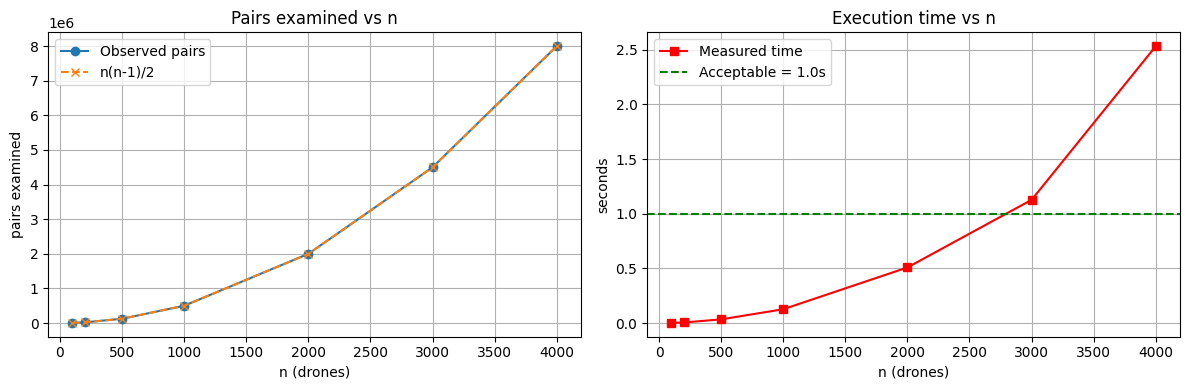

In [5]:
# ============ Q4 : Brute-force closest pair of drones ============
import random, time, math
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

def closest_pair_bruteforce(points):
    n = len(points)
    pairs_examined = 0
    dist_calcs = 0
    best = float("inf")
    best_pair = None
    for i in range(n - 1):                # i < j  -> every unordered pair exactly once
        for j in range(i + 1, n):
            pairs_examined += 1
            dx = points[i][0] - points[j][0]
            dy = points[i][1] - points[j][1]
            d2 = dx * dx + dy * dy        # squared distance (sqrt not needed for comparison)
            dist_calcs += 1
            if d2 < best:
                best = d2
                best_pair = (i, j)
    return math.sqrt(best), best_pair, pairs_examined, dist_calcs

# ---- correctness check on a tiny hand-checkable example ----
demo = [(0, 0), (10, 10), (3, 4), (11, 10), (50, 50)]
d, pr, pe, dc = closest_pair_bruteforce(demo)
print("Demo points:", demo)
print(f"Closest pair = {demo[pr[0]]} and {demo[pr[1]]}, distance = {d:.3f}, pairs examined = {pe} (expected {5*4//2})\n")

# ---- experiments ----
sizes = [100, 200, 500, 1000, 2000, 3000, 4000]
rows = []
for n in sizes:
    pts = [(random.uniform(0, 10000), random.uniform(0, 10000)) for _ in range(n)]
    t0 = time.perf_counter()
    d, pr, pe, dc = closest_pair_bruteforce(pts)
    t = time.perf_counter() - t0
    theory = n * (n - 1) // 2
    assert pe == theory and dc == theory
    rows.append([n, theory, pe, dc, round(t, 4), round(t / pe * 1e9, 1)])
df = pd.DataFrame(rows, columns=["n", "Theory n(n-1)/2", "Pairs examined", "Distance calcs",
                                 "Time (s)", "ns per pair"])
print(df.to_string(index=False))

# ---- growth ratio check: doubling n should multiply pairs by ~4 ----
print("\nGrowth when n doubles (theory ~ x4):")
for a, b in [(100, 200), (500, 1000), (1000, 2000)]:
    pa = df.loc[df.n == a, "Pairs examined"].iloc[0]
    pb = df.loc[df.n == b, "Pairs examined"].iloc[0]
    ta = df.loc[df.n == a, "Time (s)"].iloc[0]
    tb = df.loc[df.n == b, "Time (s)"].iloc[0]
    print(f"n {a} -> {b}: pairs x{pb / pa:.2f}, time x{tb / ta:.2f}")

# ---- acceptable response time & practical limit ----
ACCEPTABLE = 1.0     # seconds : our chosen criterion for real-time drone monitoring (assumption)
c = df["Time (s)"].sum() / df["Pairs examined"].sum()      # average seconds per pair
n_limit = int((1 + math.sqrt(1 + 8 * ACCEPTABLE / c)) / 2)
print(f"\nAcceptable response time = {ACCEPTABLE} s")
print(f"Measured average cost per pair = {c * 1e9:.1f} ns")
print(f"Estimated n where brute force exceeds {ACCEPTABLE} s  ~  {n_limit:,} drones")
for T in [1, 10, 60]:
    print(f"   time budget {T:>3} s  ->  n ~ {int((1 + math.sqrt(1 + 8 * T / c)) / 2):,}")

# ---- graphs ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df.n, df["Pairs examined"], "o-", label="Observed pairs")
ax[0].plot(df.n, df["Theory n(n-1)/2"], "x--", label="n(n-1)/2")
ax[0].set_xlabel("n (drones)"); ax[0].set_ylabel("pairs examined"); ax[0].set_title("Pairs examined vs n"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(df.n, df["Time (s)"], "s-", color="red", label="Measured time")
ax[1].axhline(ACCEPTABLE, color="green", linestyle="--", label=f"Acceptable = {ACCEPTABLE}s")
ax[1].set_xlabel("n (drones)"); ax[1].set_ylabel("seconds"); ax[1].set_title("Execution time vs n"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()


Test 1: boundary + interior
  hull vertices (CCW): [(0, 0), (10, 0), (10, 10), (0, 10)]
  accepted edges: 4   side-tests: 192   verified vs reference: OK

Test 2: collinear/duplicate challenge
  hull vertices (CCW): [(0, 0), (10, 0), (10, 10), (0, 10)]
  accepted edges: 4   side-tests: 240   verified vs reference: OK



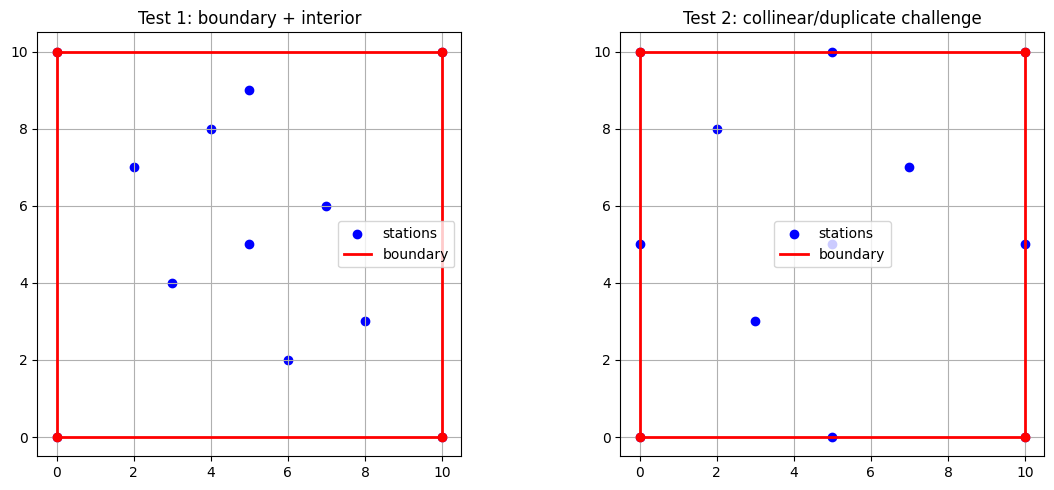

  n  Pairs n(n-1)/2  Side tests (observed, early exit)  Worst-case tests n(n-1)(n-2)/2  Hull vertices  Time (s)
 10              45                                172                             360              6    0.0002
 20             190                               1015                            3420              8    0.0011
 40             780                               4191                           29640              9    0.0050
 80            3160                              18531                          246480             12    0.0196
160           12720                              91825                         2009760             17    0.0927

Worst-case style input: all points on a circle
 n  Side tests  Hull vertices
10         227             10
20        1652             20
40       12102             40
80       91402             80


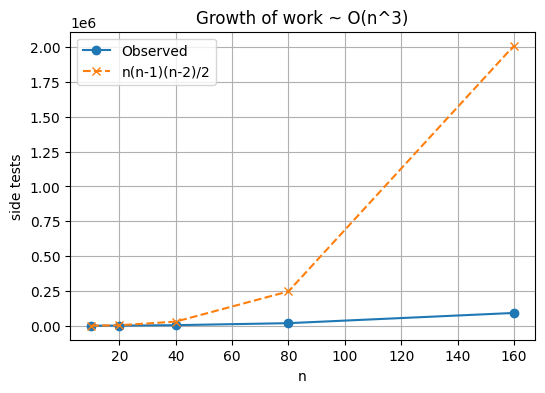

In [6]:
# ============ Q5 : Brute-force convex hull from a geometric principle ============
import random, math, time
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

def side(p, q, r):
    """Sign of a*x + b*y - c for point r w.r.t. the line through p and q.
       a = y2-y1 , b = x1-x2 , c = x1*y2 - y1*x2   (>0 one side, <0 other side, 0 on the line)"""
    a = q[1] - p[1]
    b = p[0] - q[0]
    c = p[0] * q[1] - p[1] * q[0]
    return a * r[0] + b * r[1] - c

def on_segment(p, q, r):
    """r is collinear with p,q ; is it between them (inclusive)?"""
    return (min(p[0], q[0]) <= r[0] <= max(p[0], q[0])) and (min(p[1], q[1]) <= r[1] <= max(p[1], q[1]))

def brute_force_hull(points):
    pts = list(dict.fromkeys(points))                  # remove duplicate stations
    n = len(pts)
    if n < 3:
        return pts, [], 0
    edges, tests = [], 0
    for i in range(n - 1):
        for j in range(i + 1, n):
            p, q = pts[i], pts[j]
            pos = neg = False
            ok = True
            for k in range(n):
                if k == i or k == j:
                    continue
                tests += 1
                s = side(p, q, pts[k])
                if s > 0:
                    pos = True
                elif s < 0:
                    neg = True
                elif not on_segment(p, q, pts[k]):     # collinear but outside segment -> p,q are not the extremes
                    ok = False
                    break
                if pos and neg:                        # points on both sides -> not a boundary edge
                    ok = False
                    break
            if ok:
                edges.append((p, q))
    # construct boundary : order hull vertices counter-clockwise around their centroid
    verts = list({v for e in edges for v in e})
    cx = sum(v[0] for v in verts) / len(verts)
    cy = sum(v[1] for v in verts) / len(verts)
    verts.sort(key=lambda v: math.atan2(v[1] - cy, v[0] - cx))
    return verts, edges, tests

# ---- independent reference (Andrew monotone chain) used ONLY to verify correctness ----
def reference_hull(points):
    pts = sorted(set(points))
    if len(pts) <= 2:
        return pts
    cross = lambda o, a, b: (a[0]-o[0])*(b[1]-o[1]) - (a[1]-o[1])*(b[0]-o[0])
    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0: lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0: upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]

def draw(ax, points, hull, title):
    pts = list(dict.fromkeys(points))
    ax.scatter([p[0] for p in pts], [p[1] for p in pts], c="blue", label="stations")
    hx = [v[0] for v in hull] + [hull[0][0]]
    hy = [v[1] for v in hull] + [hull[0][1]]
    ax.plot(hx, hy, "r-", linewidth=2, label="boundary")
    ax.scatter([v[0] for v in hull], [v[1] for v in hull], c="red", zorder=3)
    ax.set_title(title); ax.legend(); ax.grid(True); ax.set_aspect("equal")

# ---- Test 1 : boundary + interior points ----
test1 = [(0, 0), (10, 0), (10, 10), (0, 10), (5, 5), (3, 4), (7, 6), (4, 8), (6, 2), (2, 7), (8, 3), (5, 9)]
# ---- Test 2 : designed challenge : collinear boundary points, duplicate station, interior points ----
test2 = [(0, 0), (5, 0), (10, 0), (10, 5), (10, 10), (5, 10), (0, 10), (0, 5),   # corners + points lying ON the edges
         (5, 5), (3, 3), (7, 7), (5, 0), (2, 8)]                                  # interior + a duplicate (5,0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pts) in zip(axes, [("Test 1: boundary + interior", test1), ("Test 2: collinear/duplicate challenge", test2)]):
    hull, edges, tests = brute_force_hull(pts)
    ref = reference_hull(pts)
    assert set(hull) == set(ref), "Mismatch with reference hull!"
    print(f"{name}\n  hull vertices (CCW): {hull}\n  accepted edges: {len(edges)}   side-tests: {tests}   verified vs reference: OK\n")
    draw(ax, pts, hull, name)
plt.tight_layout(); plt.show()

# ---- growth of computational work ----
rows = []
for n in [10, 20, 40, 80, 160]:
    pts = [(random.randint(0, 1000), random.randint(0, 1000)) for _ in range(n)]
    t0 = time.perf_counter()
    hull, edges, tests = brute_force_hull(pts)
    t = time.perf_counter() - t0
    assert set(hull) == set(reference_hull(pts))
    rows.append([n, n * (n - 1) // 2, tests, n * (n - 1) * (n - 2) // 2, len(hull), round(t, 4)])
df = pd.DataFrame(rows, columns=["n", "Pairs n(n-1)/2", "Side tests (observed, early exit)",
                                 "Worst-case tests n(n-1)(n-2)/2", "Hull vertices", "Time (s)"])
print(df.to_string(index=False))

# worst case for the algorithm : all points on a circle (every point is a hull vertex -> no early exit for hull edges)
print("\nWorst-case style input: all points on a circle")
rows = []
for n in [10, 20, 40, 80]:
    pts = [(round(500 + 400 * math.cos(2 * math.pi * k / n)), round(500 + 400 * math.sin(2 * math.pi * k / n))) for k in range(n)]
    hull, edges, tests = brute_force_hull(pts)
    rows.append([n, tests, len(hull)])
print(pd.DataFrame(rows, columns=["n", "Side tests", "Hull vertices"]).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(df.n, df["Side tests (observed, early exit)"], "o-", label="Observed")
plt.plot(df.n, df["Worst-case tests n(n-1)(n-2)/2"], "x--", label="n(n-1)(n-2)/2")
plt.xlabel("n"); plt.ylabel("side tests"); plt.title("Growth of work ~ O(n^3)"); plt.legend(); plt.grid(True); plt.show()


Test 1: boundary + interior
  hull vertices (CCW): [(0, 0), (10, 0), (10, 10), (0, 10)]
  accepted edges: 4   side-tests: 192   verified vs reference: OK

Test 2: collinear/duplicate challenge
  hull vertices (CCW): [(0, 0), (10, 0), (10, 10), (0, 10)]
  accepted edges: 4   side-tests: 240   verified vs reference: OK



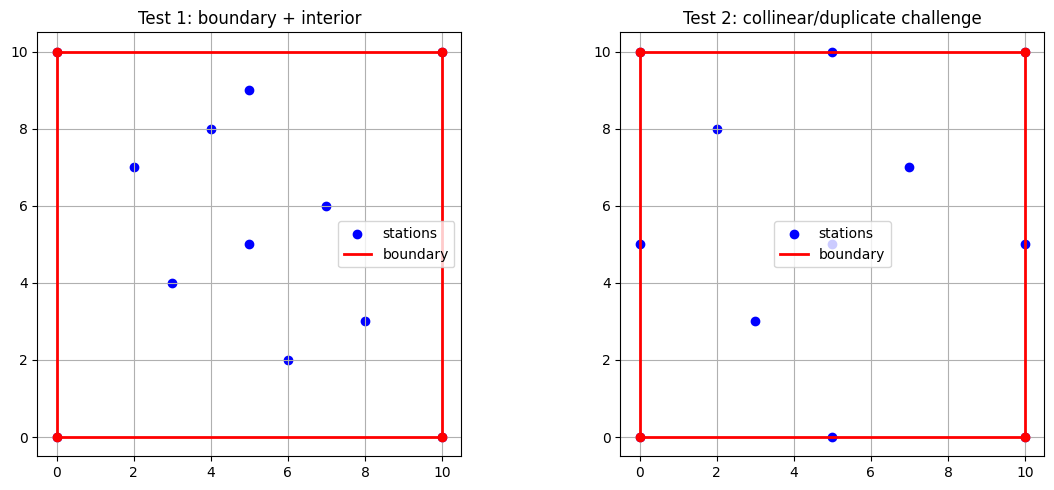

  n  Pairs n(n-1)/2  Side tests (observed, early exit)  Worst-case tests n(n-1)(n-2)/2  Hull vertices  Time (s)
 10              45                                172                             360              6    0.0002
 20             190                               1015                            3420              8    0.0007
 40             780                               4191                           29640              9    0.0026
 80            3160                              18531                          246480             12    0.0118
160           12720                              91825                         2009760             17    0.0714

Worst-case style input: all points on a circle
 n  Side tests  Hull vertices
10         227             10
20        1652             20
40       12102             40
80       91402             80


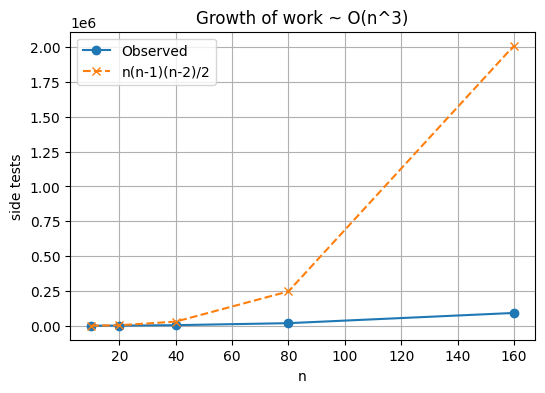

In [7]:
# ============ Q5 : Brute-force convex hull from a geometric principle ============
import random, math, time
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

def side(p, q, r):
    """Sign of a*x + b*y - c for point r w.r.t. the line through p and q.
       a = y2-y1 , b = x1-x2 , c = x1*y2 - y1*x2   (>0 one side, <0 other side, 0 on the line)"""
    a = q[1] - p[1]
    b = p[0] - q[0]
    c = p[0] * q[1] - p[1] * q[0]
    return a * r[0] + b * r[1] - c

def on_segment(p, q, r):
    """r is collinear with p,q ; is it between them (inclusive)?"""
    return (min(p[0], q[0]) <= r[0] <= max(p[0], q[0])) and (min(p[1], q[1]) <= r[1] <= max(p[1], q[1]))

def brute_force_hull(points):
    pts = list(dict.fromkeys(points))                  # remove duplicate stations
    n = len(pts)
    if n < 3:
        return pts, [], 0
    edges, tests = [], 0
    for i in range(n - 1):
        for j in range(i + 1, n):
            p, q = pts[i], pts[j]
            pos = neg = False
            ok = True
            for k in range(n):
                if k == i or k == j:
                    continue
                tests += 1
                s = side(p, q, pts[k])
                if s > 0:
                    pos = True
                elif s < 0:
                    neg = True
                elif not on_segment(p, q, pts[k]):     # collinear but outside segment -> p,q are not the extremes
                    ok = False
                    break
                if pos and neg:                        # points on both sides -> not a boundary edge
                    ok = False
                    break
            if ok:
                edges.append((p, q))
    # construct boundary : order hull vertices counter-clockwise around their centroid
    verts = list({v for e in edges for v in e})
    cx = sum(v[0] for v in verts) / len(verts)
    cy = sum(v[1] for v in verts) / len(verts)
    verts.sort(key=lambda v: math.atan2(v[1] - cy, v[0] - cx))
    return verts, edges, tests

# ---- independent reference (Andrew monotone chain) used ONLY to verify correctness ----
def reference_hull(points):
    pts = sorted(set(points))
    if len(pts) <= 2:
        return pts
    cross = lambda o, a, b: (a[0]-o[0])*(b[1]-o[1]) - (a[1]-o[1])*(b[0]-o[0])
    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0: lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0: upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]

def draw(ax, points, hull, title):
    pts = list(dict.fromkeys(points))
    ax.scatter([p[0] for p in pts], [p[1] for p in pts], c="blue", label="stations")
    hx = [v[0] for v in hull] + [hull[0][0]]
    hy = [v[1] for v in hull] + [hull[0][1]]
    ax.plot(hx, hy, "r-", linewidth=2, label="boundary")
    ax.scatter([v[0] for v in hull], [v[1] for v in hull], c="red", zorder=3)
    ax.set_title(title); ax.legend(); ax.grid(True); ax.set_aspect("equal")

# ---- Test 1 : boundary + interior points ----
test1 = [(0, 0), (10, 0), (10, 10), (0, 10), (5, 5), (3, 4), (7, 6), (4, 8), (6, 2), (2, 7), (8, 3), (5, 9)]
# ---- Test 2 : designed challenge : collinear boundary points, duplicate station, interior points ----
test2 = [(0, 0), (5, 0), (10, 0), (10, 5), (10, 10), (5, 10), (0, 10), (0, 5),   # corners + points lying ON the edges
         (5, 5), (3, 3), (7, 7), (5, 0), (2, 8)]                                  # interior + a duplicate (5,0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pts) in zip(axes, [("Test 1: boundary + interior", test1), ("Test 2: collinear/duplicate challenge", test2)]):
    hull, edges, tests = brute_force_hull(pts)
    ref = reference_hull(pts)
    assert set(hull) == set(ref), "Mismatch with reference hull!"
    print(f"{name}\n  hull vertices (CCW): {hull}\n  accepted edges: {len(edges)}   side-tests: {tests}   verified vs reference: OK\n")
    draw(ax, pts, hull, name)
plt.tight_layout(); plt.show()

# ---- growth of computational work ----
rows = []
for n in [10, 20, 40, 80, 160]:
    pts = [(random.randint(0, 1000), random.randint(0, 1000)) for _ in range(n)]
    t0 = time.perf_counter()
    hull, edges, tests = brute_force_hull(pts)
    t = time.perf_counter() - t0
    assert set(hull) == set(reference_hull(pts))
    rows.append([n, n * (n - 1) // 2, tests, n * (n - 1) * (n - 2) // 2, len(hull), round(t, 4)])
df = pd.DataFrame(rows, columns=["n", "Pairs n(n-1)/2", "Side tests (observed, early exit)",
                                 "Worst-case tests n(n-1)(n-2)/2", "Hull vertices", "Time (s)"])
print(df.to_string(index=False))

# worst case for the algorithm : all points on a circle (every point is a hull vertex -> no early exit for hull edges)
print("\nWorst-case style input: all points on a circle")
rows = []
for n in [10, 20, 40, 80]:
    pts = [(round(500 + 400 * math.cos(2 * math.pi * k / n)), round(500 + 400 * math.sin(2 * math.pi * k / n))) for k in range(n)]
    hull, edges, tests = brute_force_hull(pts)
    rows.append([n, tests, len(hull)])
print(pd.DataFrame(rows, columns=["n", "Side tests", "Hull vertices"]).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(df.n, df["Side tests (observed, early exit)"], "o-", label="Observed")
plt.plot(df.n, df["Worst-case tests n(n-1)(n-2)/2"], "x--", label="n(n-1)(n-2)/2")
plt.xlabel("n"); plt.ylabel("side tests"); plt.title("Growth of work ~ O(n^3)"); plt.legend(); plt.grid(True); plt.show()


Small instance (capacity = 10):
  P1: weight=4, value=30
  P2: weight=6, value=40
  P3: weight=3, value=20
  P4: weight=5, value=35
  P5: weight=2, value=10

All 2^5 = 32 candidate combinations:
  Mask Packages           Weight  Value  Feasible
     0 (none)                  0      0  YES
     1 P1                      4     30  YES
     2 P2                      6     40  YES
     3 P1,P2                  10     70  YES
     4 P3                      3     20  YES
     5 P1,P3                   7     50  YES
     6 P2,P3                   9     60  YES
     7 P1,P2,P3               13     90  no
     8 P4                      5     35  YES
     9 P1,P4                   9     65  YES
    10 P2,P4                  11     75  no
    11 P1,P2,P4               15    105  no
    12 P3,P4                   8     55  YES
    13 P1,P3,P4               12     85  no
    14 P2,P3,P4               14     95  no
    15 P1,P2,P3,P4            18    125  no
    16 P5                      2     10  

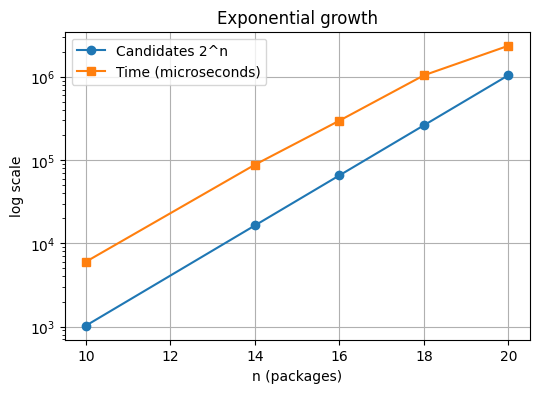

In [8]:
# ============ Q6 : Exhaustive search - helicopter payload (0/1 knapsack) ============
import random, time, math
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

def exhaustive_search(weights, values, capacity):
    """Every subset is a bit-mask: bit i = 1 means package i is loaded. 2^n candidates are generated."""
    n = len(weights)
    best_value, best_mask, feasible, examined = -1, 0, 0, 0
    for mask in range(1 << n):                 # generate every candidate
        examined += 1
        w = v = 0
        for i in range(n):                     # evaluate the candidate
            if mask >> i & 1:
                w += weights[i]
                v += values[i]
        if w <= capacity:                      # feasibility check
            feasible += 1
            if v > best_value:                 # retain the best
                best_value, best_mask = v, mask
    chosen = [i + 1 for i in range(n) if best_mask >> i & 1]
    return best_value, chosen, examined, feasible

# ---------------- Correctness check : small instance verified by hand ----------------
w_small = [4, 6, 3, 5, 2]
v_small = [30, 40, 20, 35, 10]
CAP = 10
print("Small instance (capacity = 10):")
for i in range(5):
    print(f"  P{i + 1}: weight={w_small[i]}, value={v_small[i]}")

print("\nAll 2^5 = 32 candidate combinations:")
print(f"{'Mask':>6} {'Packages':<18} {'Weight':>6} {'Value':>6}  Feasible")
for mask in range(32):
    pk = [f"P{i + 1}" for i in range(5) if mask >> i & 1]
    w = sum(w_small[i] for i in range(5) if mask >> i & 1)
    v = sum(v_small[i] for i in range(5) if mask >> i & 1)
    print(f"{mask:>6} {','.join(pk) if pk else '(none)':<18} {w:>6} {v:>6}  {'YES' if w <= CAP else 'no'}")

best, chosen, ex, fe = exhaustive_search(w_small, v_small, CAP)
print(f"\nAlgorithm result : best value = {best}, packages = {chosen}, candidates = {ex}, feasible = {fe}")
# independent verification with itertools
from itertools import combinations
check = max(sum(v_small[i] for i in c) for r in range(6) for c in combinations(range(5), r)
            if sum(w_small[i] for i in c) <= CAP)
print("Independent verification (itertools) best value =", check, "->", "MATCH" if check == best else "MISMATCH")

# ---------------- Growth investigation ----------------
print("\nGrowth investigation (random packages, capacity = 50% of total weight):")
rows = []
for n in [10, 14, 16, 18, 20]:
    w = [random.randint(5, 50) for _ in range(n)]
    v = [random.randint(10, 100) for _ in range(n)]
    cap = sum(w) // 2
    t0 = time.perf_counter()
    best, chosen, ex, fe = exhaustive_search(w, v, cap)
    t = time.perf_counter() - t0
    assert ex == 2 ** n
    rows.append([n, 2 ** n, ex, fe, best, round(t, 3)])
df = pd.DataFrame(rows, columns=["n", "Predicted 2^n", "Candidates examined", "Feasible", "Best value", "Time (s)"])
print(df.to_string(index=False))

print("\nTime ratio when n increases:")
for a, b in [(10, 14), (14, 16), (16, 18), (18, 20)]:
    ta = df.loc[df.n == a, "Time (s)"].iloc[0]; tb = df.loc[df.n == b, "Time (s)"].iloc[0]
    print(f"n {a} -> {b}: candidates x{2 ** (b - a)}, time x{tb / ta:.1f}")

# ---------------- Deployment decision ----------------
BUDGET = 10.0    # seconds : assumed maximum time the airlift planner can wait (assumption)
n_ref = int(df.n.iloc[-1]); t_ref = float(df["Time (s)"].iloc[-1])
print(f"\nResponse-time budget = {BUDGET} s  (reference: n={n_ref} took {t_ref:.2f} s)")
print("Extrapolated time (time doubles for every extra package, plus n factor for evaluation):")
n_deploy = None
for n in range(n_ref - 4, n_ref + 11):
    est = t_ref * 2 ** (n - n_ref) * (n / n_ref)
    flag = "<= budget" if est <= BUDGET else "EXCEEDS"
    if est <= BUDGET:
        n_deploy = n
    print(f"  n={n:>2}: 2^n = {2 ** n:>12,}   est. time = {est:>10.1f} s   {flag}")
print(f"\nLargest n I would deploy for a {BUDGET:.0f}s budget  ~  {n_deploy} packages")

plt.figure(figsize=(6, 4))
plt.semilogy(df.n, df["Candidates examined"], "o-", label="Candidates 2^n")
plt.semilogy(df.n, df["Time (s)"] * 1e6, "s-", label="Time (microseconds)")
plt.xlabel("n (packages)"); plt.ylabel("log scale"); plt.title("Exponential growth"); plt.legend(); plt.grid(True); plt.show()


EXPERIMENT 1 : Original vs Redesign (random packages, capacity = 50% of total weight)

 n  Original candidates  Original key ops (n*2^n)  V1 nodes  V2 nodes  Key-op reduction (orig/V2)  Orig time(s)  V1 time(s)  V2 time(s)  Optimum
10                 1024                     10240      1344        86                       119.1        0.0024      0.0005      0.0004      349
14                16384                    229376     18059       474                       483.9        0.0623      0.0067      0.0003      544
16                65536                   1048576     74864      4669                       224.6        0.4223      0.0167      0.0013      528
18               262144                   4718592    315047      6353                       742.7        0.6349      0.0735      0.0019      689
20              1048576                  20971520   1133546      6858                      3058.0        2.8750      0.2661      0.0021      920

EXPERIMENT 2 : Larger n (original would ne

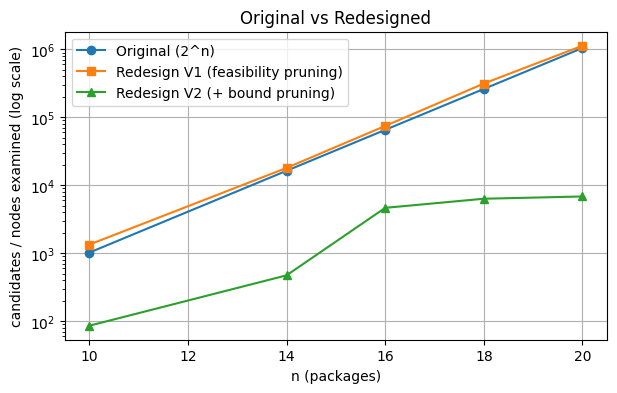

In [9]:
# ============ Q7 : Diagnose, Redesign and Validate  (chosen solution: Q6 exhaustive search) ============
import random, time, sys
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
sys.setrecursionlimit(10000)

# ---------------- ORIGINAL : exhaustive search (from Q6) ----------------
def original(weights, values, capacity):
    n = len(weights)
    best_value, best_mask = -1, 0
    weight_additions = 0                      # how many times we re-add item weights from scratch
    for mask in range(1 << n):
        w = v = 0
        for i in range(n):
            weight_additions += 1
            if mask >> i & 1:
                w += weights[i]; v += values[i]
        if w <= capacity and v > best_value:
            best_value, best_mask = v, mask
    return best_value, 1 << n, weight_additions

# ---------------- REDESIGN 1 : incremental sums + feasibility pruning ----------------
def redesign_v1(weights, values, capacity):
    n = len(weights)
    best = [0]; nodes = [0]
    def go(i, w, v):
        nodes[0] += 1                         # one partial candidate examined
        if v > best[0]:
            best[0] = v
        if i == n:
            return
        if w + weights[i] <= capacity:        # include item i only if it still fits (prunes ALL its supersets)
            go(i + 1, w + weights[i], v + values[i])
        go(i + 1, w, v)                       # exclude item i
    go(0, 0, 0)
    return best[0], nodes[0]

# ---------------- REDESIGN 2 : V1 + optimistic bound (stop if even taking ALL remaining value cannot win) ----------------
def redesign_v2(weights, values, capacity):
    n = len(weights)
    order = sorted(range(n), key=lambda i: values[i] / weights[i], reverse=True)   # preprocessing: best value-density first
    W = [weights[i] for i in order]; V = [values[i] for i in order]
    suffix = [0] * (n + 1)                    # suffix[i] = total value of items i..n-1  (extra memory O(n))
    for i in range(n - 1, -1, -1):
        suffix[i] = suffix[i + 1] + V[i]
    best = [0]; nodes = [0]
    def go(i, w, v):
        nodes[0] += 1
        if v > best[0]:
            best[0] = v
        if i == n or v + suffix[i] <= best[0]:   # bound: cannot beat the best found -> prune whole branch
            return
        if w + W[i] <= capacity:
            go(i + 1, w + W[i], v + V[i])
        go(i + 1, w, v)
    go(0, 0, 0)
    return best[0], nodes[0]

def make_instance(n, kind="random"):
    w = [random.randint(5, 50) for _ in range(n)]
    if kind == "random":
        v = [random.randint(10, 100) for _ in range(n)]
    else:                                      # strongly correlated: value = weight + 10 (hard for bound pruning)
        v = [x + 10 for x in w]
    return w, v

# ---------------- Experiment 1 : same instances for original and redesigns (capacity = 50% of total weight) ----------------
print("EXPERIMENT 1 : Original vs Redesign (random packages, capacity = 50% of total weight)\n")
rows = []
for n in [10, 14, 16, 18, 20]:
    w, v = make_instance(n)
    cap = sum(w) // 2
    t0 = time.perf_counter(); b0, c0, adds = original(w, v, cap); t_o = time.perf_counter() - t0
    t0 = time.perf_counter(); b1, c1 = redesign_v1(w, v, cap); t_1 = time.perf_counter() - t0
    t0 = time.perf_counter(); b2, c2 = redesign_v2(w, v, cap); t_2 = time.perf_counter() - t0
    assert b0 == b1 == b2, "Optimal values differ!"
    rows.append([n, c0, adds, c1, c2, round(adds / c2, 1), round(t_o, 4), round(t_1, 4), round(t_2, 4), b0])
df1 = pd.DataFrame(rows, columns=["n", "Original candidates", "Original key ops (n*2^n)", "V1 nodes", "V2 nodes", "Key-op reduction (orig/V2)",
                                  "Orig time(s)", "V1 time(s)", "V2 time(s)", "Optimum"])
print(df1.to_string(index=False))

# ---------------- Experiment 2 : sizes the original cannot handle ----------------
print("\nEXPERIMENT 2 : Larger n (original would need 2^n candidates; V1 skipped because it is still too slow here)\n")
rows = []
for n in [25, 30, 35]:
    w, v = make_instance(n)
    cap = sum(w) // 2
    t0 = time.perf_counter(); b2, c2 = redesign_v2(w, v, cap); t_2 = time.perf_counter() - t0
    rows.append([n, f"{2 ** n:,}", f"{n * 2 ** n:,}", f"{c2:,}", round(t_2, 3), f"{round(2 ** n / c2):,}x"])
print(pd.DataFrame(rows, columns=["n", "Original candidates 2^n", "Original key ops n*2^n", "V2 nodes", "V2 time(s)", "Candidates avoided"]).to_string(index=False))

# ---------------- Experiment 3 : effect of capacity and data type (trade-off analysis, n = 20) ----------------
print("\nEXPERIMENT 3 : When does the redesign help less?  (n = 20)\n")
rows = []
for kind in ["random", "correlated"]:
    w, v = make_instance(20, kind)
    for frac in [0.25, 0.50, 0.90]:
        cap = int(sum(w) * frac)
        b1, c1 = redesign_v1(w, v, cap)
        b2, c2 = redesign_v2(w, v, cap)
        b0 = max(b1, b2)
        assert b1 == b2
        rows.append([kind, f"{int(frac * 100)}%", 2 ** 20, c1, c2, round(2 ** 20 / c2, 1)])
print(pd.DataFrame(rows, columns=["Data", "Capacity", "Original 2^20", "V1 nodes", "V2 nodes", "Reduction"]).to_string(index=False))

# ---------------- Graph ----------------
plt.figure(figsize=(7, 4))
plt.semilogy(df1.n, df1["Original candidates"], "o-", label="Original (2^n)")
plt.semilogy(df1.n, df1["V1 nodes"], "s-", label="Redesign V1 (feasibility pruning)")
plt.semilogy(df1.n, df1["V2 nodes"], "^-", label="Redesign V2 (+ bound pruning)")
plt.xlabel("n (packages)"); plt.ylabel("candidates / nodes examined (log scale)")
plt.title("Original vs Redesigned"); plt.legend(); plt.grid(True); plt.show()
